In [1]:
%config InlineBackend.figure_formats = ['svg']
import numpy as np
import matplotlib.pyplot as plt
#%matplotlib inline
#plt.rcParams['figure.figsize'] = [9.5, 3]

# DAT171 Computer Assignment 1

# Step 2: Visualizing data

Now when we have the cleanded the experimental results stored in a `pkl` file format it is time to study the particle dynamics. The analysis developed here will be reused in Step 3.

The goal is to compute several statistical and ensemble properties of the particles using NumPy and visualize them using Matplotlib.

Write a single python file with the name `ca1_step2_solution.py`
that implements the analysis and the helper functions specified below.

## Read data from file

Read the `ca1_step1_output_data.pkl` file and put the data in the variables `R`, `V`, `radius`, `time_step`, and `v_variance`.

In [2]:
# -- Solution

import pickle
with open('ca1_step1_output_data.pkl', 'rb') as fd:
    R, V, radius, time_step, v_variance = pickle.load(fd)

## Structure of the data

The experimental data contains the positions `R` and velocities `V` of an ensemble of particles constrained on the square $x,y \in [-1, 1]$. Your data contains snapshots of the positions and velocities at regular time intervals with a separation of `time_step` seconds.

Check the index order defined in Step 1 and plot the y-position of particle number `123` as a function of time `t` by correctly indexing the position data in `R`.

Use the numpy function `np.arange` and the `time_step` length in seconds to make a vector of the times `t` that the snapshots of the particles are done at and use it when plotting.

The result should look like:

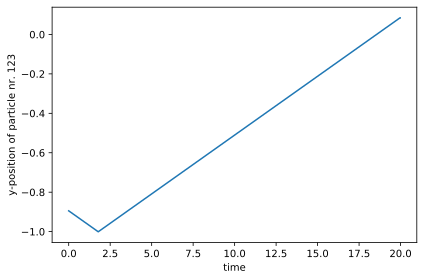

In [3]:
# -- Solution

t = time_step * np.arange(R.shape[0])

plt.plot(t, R[:, 1, 123], '-')
plt.xlabel('time')
plt.ylabel('y-position of particle nr. 123')
plt.tight_layout()

## Total kinetic energy and total velocity

Start the analysis by computing the average total kinetic energy `E_k` and total velocity `V_tot` for all particles as a function of time.

The total kinetic energy of the particles $E_k$ is is given by
$$ 
E_k = \sum_{i=1}^N \frac{m_i \vec{v}_i^2}{2}
$$
were $\vec{v}_i$ is the velocity vector and $m_i$ is the mass of the particle with index $i$ and $N$ is the total number of particles. Assume that the masses $m_n$ are all equal to unity, $m_i = 1$.

The total velocity $V_{tot}$ of all particles per time step is defined as the norm of the sum of all particle veolcities
$$
V_{tot} = \Big| \sum_{i=1}^N \vec{v}_i \Big|
$$

- To compute sums use the `np.sum(data, axis=n)` to sum over the `n`th axis of an `ndarray`. 
- To compute vector norms use the `np.linalg.norm(data, axis=n)` function.

Make sure to use Numpy broadcasting and reduction operations in the calculations. In particular avoid using loop constructs for the cauclations.

Plotting `E_k` and `V_tot` as a function of time should look like:

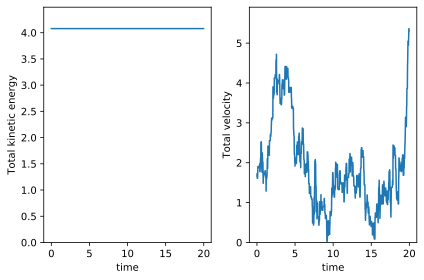

In [15]:
# -- SOLUTION

E = 0.5 * np.sum(V**2, axis=(1,2))
V_tot = np.linalg.norm(np.sum(V, axis=-1), axis=-1)

subp = [1, 2, 1]

plt.subplot(*subp); subp[-1] += 1
plt.plot(t, E)
plt.ylim(bottom=0, top=np.max(E)*1.1)
plt.xlabel('time')
plt.ylabel('Total kinetic energy')

plt.subplot(*subp); subp[-1] += 1
plt.plot(t, V_tot)
plt.ylim(bottom=0, top=np.max(V_tot)*1.1)
plt.xlabel('time')
plt.ylabel('Total velocity')

plt.tight_layout()

## Position and velocity histograms

To understand the dynamics we would like to study the probability distribution of positions and velocities for all particles and all times.

Use the `matplotlib` histogram plot `plt.hist` to plot these histograms
- <https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.hist.html>

Given the histograms, what simplified model distributions could be used to approximate
- the $x$ and $y$ positions?
- the $v_x$ and $v_y$ velocities?

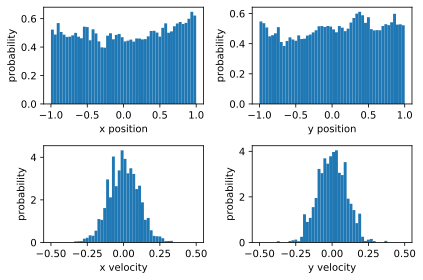

In [5]:
# -- SOLUTION

x = R[:, 0, :]
y = R[:, 1, :]

v_x = V[:, 0, :]
v_y = V[:, 1, :]

def plot_hist(data, range=(-1, 1), xlabel=None, bins=50, subp=None, **kwargs):
    if subp is not None: 
        plt.subplot(*subp)
        subp[-1] += 1
    plt.hist(data.flatten(), range=range, density=True, bins=bins, **kwargs)
    plt.ylabel('probability')
    plt.xlabel(xlabel)

opts = dict(subp=[2, 2, 1], bins=50)
plot_hist(x, xlabel='x position', **opts)
plot_hist(y, xlabel='y position', **opts)
opts['range'] = (-0.5, 0.5)
plot_hist(v_x, xlabel='x velocity', **opts)
plot_hist(v_y, xlabel='y velocity', **opts)
plt.tight_layout()

## Fitting probability distributions

Decide on reasonable model distribution functions that could be used to fit the experimental data. We now want to fit the model parameters to the experimental data and ovelay the fitted model probability function for both the positions and the velocities on the experimental histogram plots.

To fit and visualize the model distributions (of the positions and velocities), use the model distributions provided in the SciPy statistics module `scipy.stats`.
- <https://docs.scipy.org/doc/scipy/reference/tutorial/stats.html>
- <https://docs.scipy.org/doc/scipy/reference/stats.html>

All model distribution implements a `.fit(data)` method that gives a maximum likely hood fit of the model parameters. Use this to fit the particle data.

Here is an example plot with a fit using the `scipy.stats.uniform` distribution function
- <https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.uniform.html>

loc, scale = -1.0052574337933184 2.0101246406304507


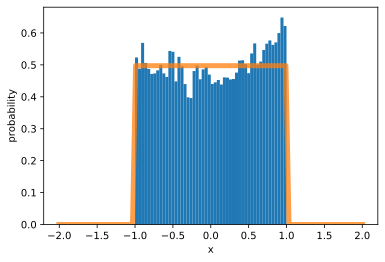

In [6]:
# -- Solution (Single example)

import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

x = R[:, 0, :]
loc, scale = stats.uniform.fit(x.flatten())
print('loc, scale =', loc, scale)

X = np.linspace(-1 + loc, loc + scale + 1, num=100)
pdf = stats.uniform.pdf(X, loc, scale)

plt.hist(x.flatten(), bins=50, density=True, range=(-1, 1))
plt.plot(X, pdf, lw=5, alpha=0.75)
plt.ylabel('probability')
plt.xlabel('x');

Make plots with histogram data and theoretical distribution functions for:
- the $x$ and $y$ positions, and
- the $v_x$ and $v_y$ velocities.


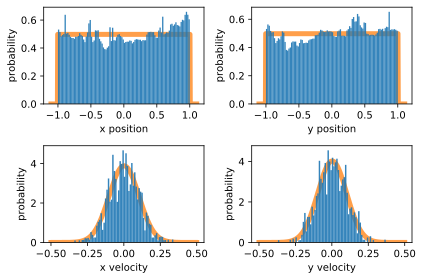

In [7]:
# -- SOLUTION

# -- Fit uniform distribution for the positions

loc_x, scale_x = stats.uniform.fit(x.flatten())
loc_y, scale_y = stats.uniform.fit(y.flatten())

#print('loc x, y =', loc_x, loc_y)
#print('scale x, y =', scale_x, scale_y)
#print()

# -- Fit Normal distribution for the velocities

mu_x, sigma_x = stats.norm.fit(v_x.flatten())
mu_y, sigma_y = stats.norm.fit(v_y.flatten())

#print('mu x,y =', mu_x, mu_y)
#print('sigma x,y =', sigma_x, sigma_y)
#print()

# -- Plotting

opts = dict(subp=[2, 2, 1], bins=100, alpha=0.9)
pdf_opts = dict(zorder=-100, alpha=0.75, lw=5)

# Positions

X = np.linspace(x.min() * 1.1, x.max() * 1.1, num=500)

plot_hist(x, xlabel='x position', **opts)
plt.plot(X, stats.uniform.pdf(X, loc_x, scale_x), **pdf_opts)

plot_hist(y, xlabel='y position', **opts)
plt.plot(X, stats.uniform.pdf(X, loc_y, scale_y), **pdf_opts)

# Velocities

vv = np.linspace(-0.5, 0.5, num=500)
opts['range'] = (vv.min(), vv.max())

plot_hist(v_x, xlabel='x velocity', **opts)
plt.plot(vv, stats.norm.pdf(vv, mu_x, sigma_x), **pdf_opts)
plot_hist(v_y, xlabel='y velocity', **opts)
plt.plot(vv, stats.norm.pdf(vv, mu_y, sigma_y), **pdf_opts)

plt.tight_layout()


## Speed distribution

Compute the speed of each particle as a function of time. The speed of particle $i$ is defined as the norm of the velocity vector $|\vec{v}_n|$.

Plot the histogram of the speeds of all particles at all times together with a fitted model distribution function. (In this case it turns out that the Rayleigh distribution `scipy.stats.rayleigh` is a decent fit.)

The result should look similar to:

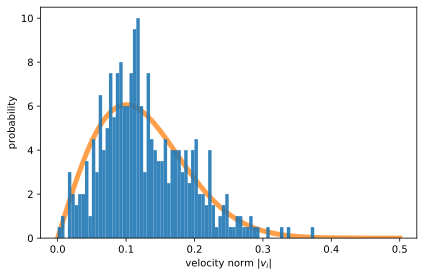

In [17]:
# -- SOLUTION

norm_V = np.linalg.norm(V, axis=1)

range = np.array([0., 0.5])
x = np.linspace(range.min(), range.max(), num=100)
pdf = stats.rayleigh.pdf(x, loc=0, scale=v_variance)

plot_hist(norm_V, range=range, bins=100, alpha=0.9, 
          xlabel='velocity norm $|v_i|$')
plt.plot(x, pdf, lw=5, alpha=0.75, zorder=-100)
plt.tight_layout()

## Pair distribution function

To look for correlations between the particles we are also interested in the probability distribution of distances between all pairs of particles for all times. This probability distribution is called *the pair distribution function* and is given by the histogram of the distances $d_{ij}$ between all pairs $i$ and $j$ of particles, $j \ne i$.

The distance $d_{ij}$ is given by the norm of the difference between the position vectors $r_i$ and $r_j$ of particle $i$ and $j$ respectively
$$ d_{ij} \equiv | \vec{r}_i - \vec{r}_j | $$

Compute $d_{ij}$ for all pairs of particles for all times and plot its histogram. Make sure not to include the distance between the same particle, i.e. the case when $i = j$.

The results for the experimental data set should look like:

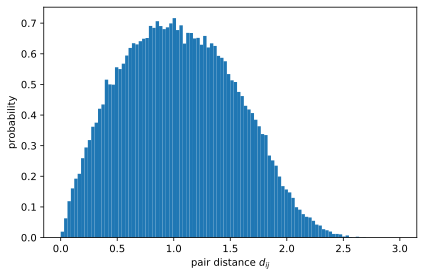

In [16]:
# -- Solution

r = R[-1, :, :]

dr = np.linalg.norm(r[:, :, None] - r[:, None, :], axis=0)
dr -= np.eye(r.shape[-1])

plt.hist(dr.flatten(), range=(0., 3.), bins=100, density=True)
plt.xlabel('pair distance $d_{ij}$')
plt.ylabel('probability')
plt.tight_layout()

## Combined statistical analysis function

Write a function that implements the analysis in all the steps above, with the following function signature
```python
def plot_statistical_analysis(R, V, time_step, filename):
   ...
```
The function should collect all the plots in a figure with multiple sub plots and write the result to the file with the name specified by the `filename` variable.

Run the function on the experimental data and store the result in the file `ca1_step2_figure_summary.svg`, and hand it in with your solution.

The result should look something like:

In [10]:
# -- Solution

import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

def plot_statistical_analysis(R, V, time_step, filename):
    """Perform all statistical analysis in ca1 step2 and plot
    result in a single figure. """

    bins = 100
    bins_fine = 400
    N_time_steps_in_pdf = 10

    Nt = R.shape[0]
    N = R.shape[-1]

    t = np.arange(Nt) * time_step

    r_tin = R
    v_tin = V

    x_tn = R[:, 0]
    y_tn = R[:, 1]

    vx_tn = V[:, 0]
    vy_tn = V[:, 1]

    norm_v2_tn = np.sum(v_tin ** 2, axis=1)
    E_t = np.sum(norm_v2_tn, axis=-1)
    Vtot_t = np.linalg.norm(np.sum(v_tin, axis=-1), axis=-1)

    # -- Pair distribution function
    N_steps = 5
    dr = np.linalg.norm(R[-N_steps:-1, :, :, None] - R[-N_steps:-1, :, None, :], axis=1)
    dr += -np.eye(N)[None, :, :]

    subp = [4, 2, 1]
    v_variance = 0.1
    v_range = (-4 * v_variance, 4 * v_variance)
    norm_v_range = (0., 4 * v_variance)
    r_range = (-1., 1.)

    fig = plt.figure(figsize=(6, 6))

    ax = plt.subplot(*subp);
    subp[-1] += 1
    plt.plot(t, Vtot_t)
    plt.xlabel('time')
    plt.ylabel('Average speed')

    ax = plt.subplot(*subp);
    subp[-1] += 1
    plt.plot(t, E_t)
    E_mean = np.mean(E_t)
    plt.ylim([0.99 * E_mean, 1.01 * E_mean])
    plt.xlabel('time')
    plt.ylabel('Kinetic Energy')

    ax = plt.subplot(*subp);
    subp[-1] += 1
    plt.hist(dr.flatten(), range=(0., 3.), bins=200, density=True)
    plt.xlabel('distance')
    plt.ylabel('Pair distribution\nprobability')

    ax = plt.subplot(*subp);
    subp[-1] += 1
    plt.hist(np.sqrt(norm_v2_tn.flatten()), range=norm_v_range, bins=bins, density=True)
    x = np.linspace(norm_v_range[0], norm_v_range[1], num=500)
    plt.plot(x, stats.chi.pdf(x / v_variance, 2) / v_variance, '-', alpha=0.74)
    plt.xlabel('speed')
    plt.ylabel('Velocity norm\nprobability')

    ax = plt.subplot(*subp);
    subp[-1] += 1
    plt.hist(x_tn.flatten(), range=r_range, bins=bins, density=True)
    plt.ylim([0, 1])
    plt.xlabel('x position')
    plt.ylabel('probability')

    ax = plt.subplot(*subp);
    subp[-1] += 1
    plt.hist(y_tn.flatten(), range=r_range, bins=bins, density=True)
    plt.ylim([0, 1])
    plt.xlabel('y position')
    plt.ylabel('probability')

    ax = plt.subplot(*subp);
    subp[-1] += 1
    plt.hist(vx_tn.flatten(), range=v_range, bins=bins, density=True)
    x = np.linspace(v_range[0], v_range[1], num=500)
    plt.plot(x, stats.norm.pdf(x, 0., v_variance), '-', alpha=0.74)
    plt.xlabel('x velocity')
    plt.ylabel('probability')

    ax = plt.subplot(*subp);
    subp[-1] += 1
    plt.hist(vy_tn.flatten(), range=v_range, bins=bins, density=True)
    x = np.linspace(v_range[0], v_range[1], num=500)
    plt.plot(x, stats.norm.pdf(x, 0., v_variance), '-', alpha=0.74)
    plt.xlabel('y velocity')
    plt.ylabel('probability')

    plt.tight_layout()
    plt.savefig(filename)

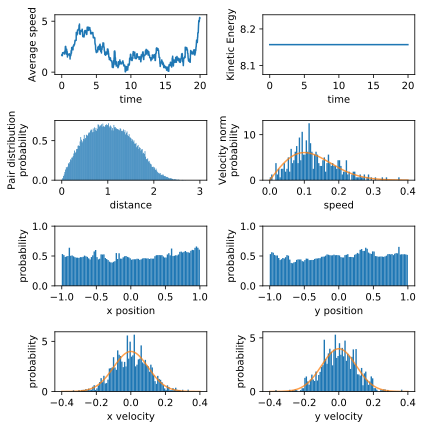

In [11]:
plot_statistical_analysis(R, V, time_step, filename='ca1_step2_figure_summary.svg')

## Animate the particle trajectories

To get a more intuitive feeling for how the particles are behaving we will, as a last step, slightly misuse Matplotlib and animate the evolution of the particles.

If you are intersted in the details on Matplotlib animations, see:
- <https://matplotlib.org/3.1.1/api/animation_api.html>
- <https://matplotlib.org/gallery/animation/basic_example_writer_sgskip.html>

Here we will simply use the supplied function `aminate_particles(...)`, see below, to generate movies of the particle dynamics. Copy-paste the function into your solution script `ca1_step2_solution.py` and use it to render a movie of the particles. Store it to the file `ca1_step2_movie.mp4`.

In [12]:
import os
import matplotlib.pyplot as plt
import matplotlib.animation as animation

def animate_particles(R, time_step, filename='movie.mp4'):
    """Generates an mp4 movie with the particle trajectories
    using MatPlotLib. """

    if os.path.isfile(filename):
        print('WARNING (animate_particles): The output file', filename, 'exists. Skipping animation.')
        return

    frames = R.shape[0]
    frames_per_second = 1. / time_step

    fig = plt.figure(figsize=(6, 6))
    ax = plt.subplot()

    plt.xlabel('x')
    plt.ylabel('y')
    plt.axis('image')
    plt.xlim([-1.0, 1.0])
    plt.ylim([-1.0, 1.0])

    markers = ax.scatter([], [], s=40, alpha=0.5)
    text = plt.text(-0.9, 0.9, 'frame =', ha='left')

    def update(frame, markers, text):
        print('frame =', frame)
        r = R[frame]
        markers.set_offsets(r.T)
        text.set_text('frame = {}'.format(frame))

    anim = animation.FuncAnimation(
        fig, update,
        frames=frames, interval=50,
        fargs=(markers, text),
        blit=False, repeat=False,
    )

    writer = animation.writers['ffmpeg'](fps=frames_per_second)
    anim.save(filename, writer=writer, dpi=100)
    plt.close()

In [13]:
animate_particles(R, time_step, filename='ca1_step1_movie.mp4')

frame = 0
frame = 0
frame = 1
frame = 2
frame = 3
frame = 4
frame = 5
frame = 6
frame = 7
frame = 8
frame = 9
frame = 10
frame = 11
frame = 12
frame = 13
frame = 14
frame = 15
frame = 16
frame = 17
frame = 18
frame = 19
frame = 20
frame = 21
frame = 22
frame = 23
frame = 24
frame = 25
frame = 26
frame = 27
frame = 28
frame = 29
frame = 30
frame = 31
frame = 32
frame = 33
frame = 34
frame = 35
frame = 36
frame = 37
frame = 38
frame = 39
frame = 40
frame = 41
frame = 42
frame = 43
frame = 44
frame = 45
frame = 46
frame = 47
frame = 48
frame = 49
frame = 50
frame = 51
frame = 52
frame = 53
frame = 54
frame = 55
frame = 56
frame = 57
frame = 58
frame = 59
frame = 60
frame = 61
frame = 62
frame = 63
frame = 64
frame = 65
frame = 66
frame = 67
frame = 68
frame = 69
frame = 70
frame = 71
frame = 72
frame = 73
frame = 74
frame = 75
frame = 76
frame = 77
frame = 78
frame = 79
frame = 80
frame = 81
frame = 82
frame = 83
frame = 84
frame = 85
frame = 86
frame = 87
frame = 88
frame = 89
frame = 90

frame = 692
frame = 693
frame = 694
frame = 695
frame = 696
frame = 697
frame = 698
frame = 699
frame = 700
frame = 701
frame = 702
frame = 703
frame = 704
frame = 705
frame = 706
frame = 707
frame = 708
frame = 709
frame = 710
frame = 711
frame = 712
frame = 713
frame = 714
frame = 715
frame = 716
frame = 717
frame = 718
frame = 719
frame = 720
frame = 721
frame = 722
frame = 723
frame = 724
frame = 725
frame = 726
frame = 727
frame = 728
frame = 729
frame = 730
frame = 731
frame = 732
frame = 733
frame = 734
frame = 735
frame = 736
frame = 737
frame = 738
frame = 739
frame = 740
frame = 741
frame = 742
frame = 743
frame = 744
frame = 745
frame = 746
frame = 747
frame = 748
frame = 749
frame = 750
frame = 751
frame = 752
frame = 753
frame = 754
frame = 755
frame = 756
frame = 757
frame = 758
frame = 759
frame = 760
frame = 761
frame = 762
frame = 763
frame = 764
frame = 765
frame = 766
frame = 767
frame = 768
frame = 769
frame = 770
frame = 771
frame = 772
frame = 773
frame = 774
fram

Your result should look simiar to:

In [14]:
from IPython.display import Video
Video('ca1_step1_movie.mp4', embed=True)

## Computer Assignment 1 Step 2: Deliverables¶

Hand in your solution to Step 2 as a single python file with the name `ca1_step2_solution.py`, also supply your summary plot `ca1_step2_figure_summary.svg`.

Please also follow the general guidelines for the computer assignments, see separate document on the course home page.